In [308]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

In [ ]:
"""Interspike interval statistics of a noisy integrate-and-fire neuron.

    du/dt = -alpha*u + Ibar + noise,   reset u -> 0 at u = 1

With subthreshold drive (Ibar below threshold) the neuron cannot fire
without noise at all, so every spike is noise-driven and the ISI
distribution is a first-passage density: sharply peaked with a long right
tail, nothing like the delta a deterministic model gives. Raising sigma
raises the firing rate even though the mean input has not changed, which
is the point of the model.

Two ways to collect ISIs, both here:
  - one long simulation, taking differences of spike times
  - many short first-passage runs, each stopped at threshold

The second gives a fixed sample size, so histograms are easier to compare
across parameters.

Uses lif_sim from lif_sim.py for the trace, rather than repeating the
integration loop as Noisy_IF.ipynb did twice more.

Fixed from the original: the first-passage loop wrote isi[j-1] instead of
isi[j], so entry 0 was never assigned and stayed exactly zero while entry
nsim-1 was written twice. One spurious zero interval in every sample
pulled the mean down and inflated the variance. The notebook also
demonstrated noise with rnd.rand() (uniform) where rnd.randn() (normal)
was meant.

Regression check: with Ibar = 0.95, sigma = 0.1 the two methods should
agree on the mean ISI to within sampling error. No ISI should be zero; if
one is, the off-by-one is back.
"""

In [264]:
def decision(d_0, theta, dt, l, mu, sigma_sq, trials):
    results = np.zeros(trials)
    d_times = np.zeros(trials)
    rng = np.random.default_rng()
    for q in range(trials):
        t = 0
        d = d_0
        while np.abs(d) < theta:
            # decision has not been made - we take a step in time
            dd_dt = l*d + mu
            d += dd_dt*dt + np.sqrt(2 * dt*sigma_sq) * rng.standard_normal()
            t += dt
        # if we get here, we have reached a decision
        results[q] = d > 0
        d_times[q] = t
    return np.mean(results), np.mean(d_times)

In [176]:
#test_results, test_decisions = decision(5, 5, 4, .002, .5, .5, .2, 5, .25, 100)

In [221]:
# 100 trials when theta = 4 takes 15 seconds. 10,000 trials would take 25 minutes
# I think running the whole loop is going to take ~100 minutes

In [335]:
## all stuff for lambda = 0
theta_vals = np.array([.5, 1, 1.5, 2, 2.5, 3, 3.5, 4])
dec = [decision(0, theta, .002, 0, 0.2, 0.25, 10000) for theta in theta_vals]
dec2 = [decision(0, theta, .002, 0.2, 0.2, 0.25, 10000)for theta in theta_vals]

In [286]:
theo_correct1 = [1/(1 + np.e**(-.2*theta/.25)) for theta in theta_vals] 
theo_times1 = [theta/.2*np.tanh(.2*theta/(.5)) for theta in theta_vals]

In [312]:
def g(l, mu, sigma, y):
    return np.e**(-1*(l*y**2 + 2*mu*y)/(2*sigma**2))

def g2(y):
    return g(0.2, 0.2, 0.5, y)

In [337]:
theo_correct2 = [quad(g2, -theta, 0)[0]/quad(g2, -theta, theta)[0] for theta in theta_vals]
theo_correct2

[0.5970999790118173,
 0.6788996244037152,
 0.7380576469196148,
 0.7756540695685517,
 0.7968987395724263,
 0.8075057936228662,
 0.8120950137739769,
 0.8137776524747321]

In [341]:
correct1, times1 = zip(*dec)
correct2, times2 = zip(*dec2)

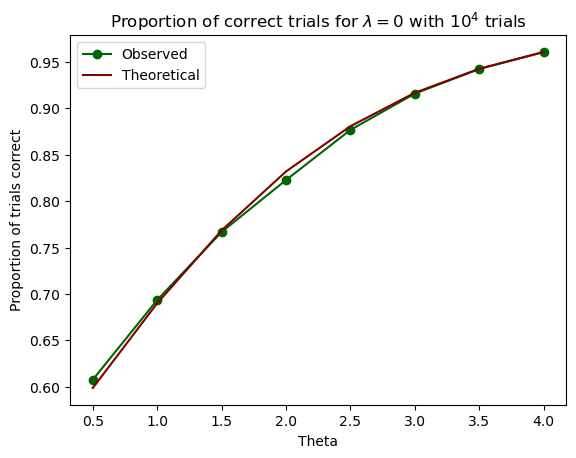

In [348]:
plt.plot(theta_vals, correct1, "-o", label = "Observed",
        color = "darkgreen")
plt.plot(theta_vals, theo_correct1, label = "Theoretical",
        color = "maroon")
plt.legend()
plt.xlabel("Theta")
plt.ylabel("Proportion of trials correct")
plt.title(r"Proportion of correct trials for $\lambda = 0$ with $10^4$ trials")
plt.savefig("propcorrect1", dpi = 300, bbox_inches = "tight")
plt.show()

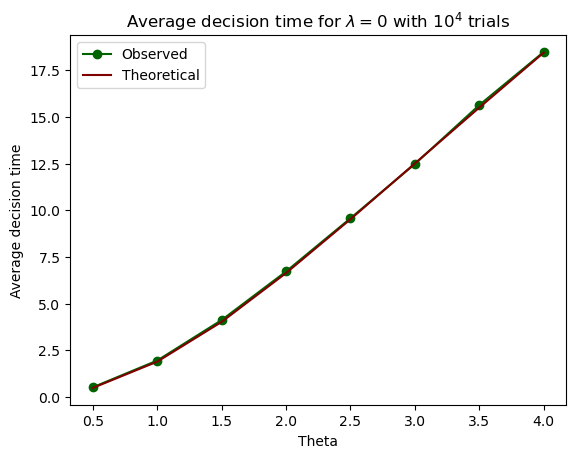

In [350]:
plt.plot(theta_vals, times1, "-o", label = "Observed",
        color = "darkgreen")
plt.plot(theta_vals, theo_times1, label = "Theoretical",
        color = "maroon")
plt.legend()
plt.xlabel("Theta")
plt.ylabel("Average decision time")
plt.title(r"Average decision time for $\lambda = 0$ with $10^4$ trials")
plt.savefig("dectime", dpi = 300, bbox_inches = "tight")
plt.show()

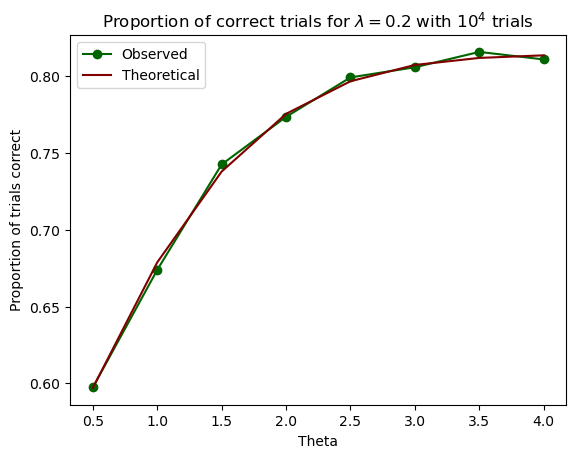

In [352]:
plt.plot(theta_vals, correct2, "-o", label = "Observed",
        color = "darkgreen")
plt.plot(theta_vals, theo_correct2, label = "Theoretical",
        color = "maroon")
plt.legend()
plt.xlabel("Theta")
plt.ylabel("Proportion of trials correct")
plt.title(r"Proportion of correct trials for $\lambda = 0.2$ with $10^4$ trials")
plt.savefig("propcorrect2", dpi = 300, bbox_inches = "tight")
plt.show()

In [359]:
correct2[-1], times2[-1]

(0.8111, 8.331407199999857)